<a href="https://colab.research.google.com/github/asegura4488/EDCO_IntroCienciaDatos/blob/main/Semana5/MediaMovil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive
from google.colab import files
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.chdir('/content/drive/MyDrive/EDCO_IntroCienciaDatos/Semana4')
!ls

Datos		    LimpiezaExcel.ipynb   RegresionLinealConceptos.ipynb
LimpiezaBase.ipynb  RegresionCarro.ipynb


In [8]:
Data = pd.read_csv('Datos/MediaMovilData.csv')
Data
x = Data['Ventas'].values
x

array([1250, 1150,  970, 1100, 1170, 1080, 1120, 1230, 1210, 1050, 1030,
        990, 1160, 1200, 1180, 1260, 1230, 1190])

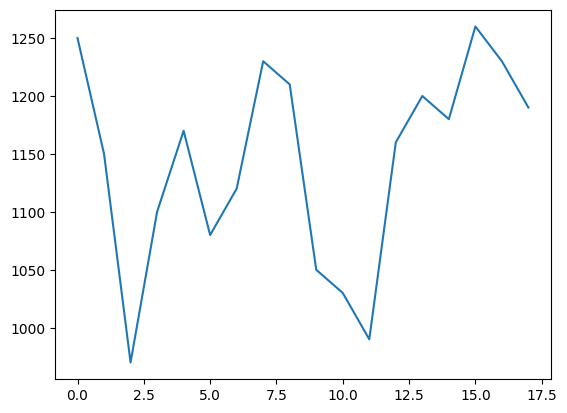

In [9]:
plt.plot(Data)

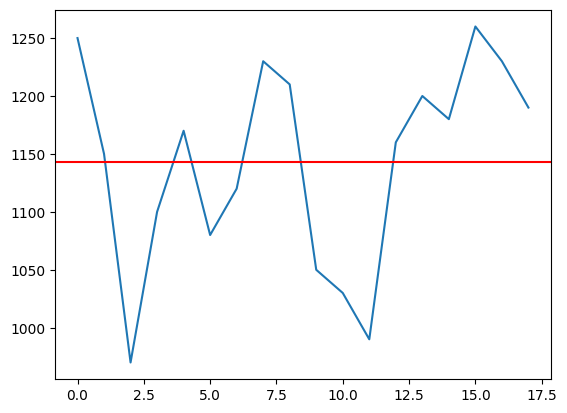

In [10]:
media = np.mean(Data)
plt.plot(Data)
plt.axhline(media,color='r')

In [11]:
# Vamos a construir un modelo de media movil
# Usar la informacion cercana al punto de predección ( $ Markoviana)
# Nuestro modelo depende de dias anteriores

In [25]:
def GetMediaMovil(x,n):

  media = np.zeros( len(x) + 1 )

  for i in range( len(media) ):

    sum_ = 0.

    if i >= n:

      for j in range( i-n, i ):

        sum_ += x[j]

      media[i] = sum_/n # Promedio simple

    else:

      media[i] = x[i]

  return media

In [36]:
media_ = GetMediaMovil(x,3)
media_[-1]

np.float64(1226.6666666666667)

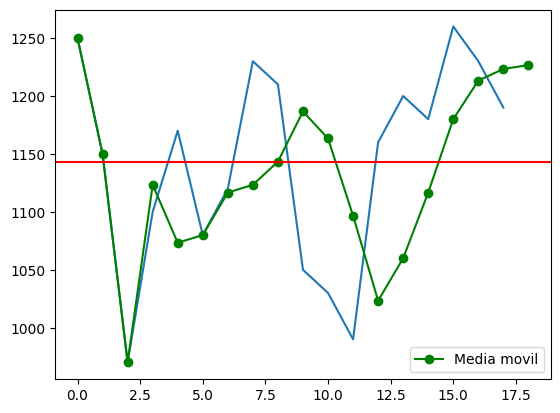

In [37]:
media = np.mean(Data)
plt.plot(Data)
plt.plot(media_,marker='o',color='g',label='Media movil')
plt.axhline(media,color='r')
plt.legend()

In [38]:
# Hallar una metrica
def GetError(x,y):
  return np.mean( np.abs(x-y) )

In [39]:
GetError(x,media_[:-1])
# UNa valor de confianza

np.float64(63.518518518518526)

In [40]:
media_[-1]

np.float64(1226.6666666666667)

In [42]:
# Cual es el siguiente punto: Mejoremos el modelo
# Sería hacer una media movil ponderada
# ventas = x1 * w1 + x2 * w2 + x3 * w3

In [43]:
def GetWeightedMediaMovil(x,w):

  # W es el vector de pesos
  n = len(w)

  media = np.zeros( len(x) + 1 )

  for i in range( len(media) ):

    sum_ = 0.

    if i >= n:

      k = 0

      for j in range( i-n, i ):

        sum_ += w[k]*x[j]
        k += 1

      media[i] = sum_ # Promedio ponderado

    else:

      media[i] = x[i]

  return media

In [72]:
w = np.array([0.1,0.3,0.6])
media_w = GetWeightedMediaMovil(x,w)
media_w[-1]

np.float64(1209.0)

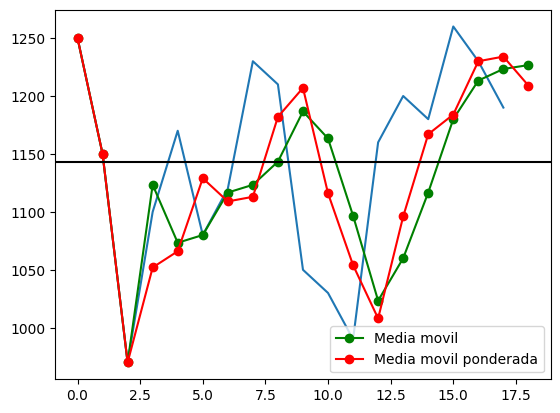

In [73]:
media = np.mean(Data)
plt.plot(Data)
plt.plot(media_,marker='o',color='g',label='Media movil')
plt.plot(media_w,marker='o',color='r',label='Media movil ponderada')
plt.axhline(media,color='k')
plt.legend()

In [74]:
GetError(x,media_[:-1])

np.float64(63.518518518518526)

In [75]:
GetError(x,media_w[:-1])

np.float64(58.5)

In [76]:
# Queremos encontrar le mejor modelo posible!!

In [77]:
def Cost(w):
  # QUeremos minimizar el error promedio del modelo
  media_w = GetWeightedMediaMovil(x,w)
  return GetError(x,media_w[:-1])

In [78]:
Cost([0.5,0.35,0.15])

np.float64(74.61111111111111)

In [79]:
# Usamos un paquete de optimizacion (optimize)
import scipy.optimize as optimize
from scipy.stats import norm

In [80]:
constraints = ( {'type':'eq', 'fun' : lambda w : np.sum(w) - 1} )
bounds = ( (0,1), (0,1), (0,1) ) # Los valores que no puedo tocar
w0 = np.array([0.1,0.2,0.8])
result = optimize.minimize(Cost,w0,constraints=constraints,bounds=bounds)
result
#

     message: Optimization terminated successfully
     success: True
      status: 0
         fun: 54.51851920654363
           x: [ 1.333e-01  2.983e-13  8.667e-01]
         nit: 28
         jac: [-1.706e+02 -1.578e+02 -1.711e+02]
        nfev: 177
        njev: 28
 multipliers: [-1.706e+02]

In [81]:
wopt = result.x
print(np.round(wopt,2))

[0.13 0.   0.87]


In [82]:
Woptimizada = GetWeightedMediaMovil(x,wopt)
Woptimizada[-1]

np.float64(1199.333420024494)

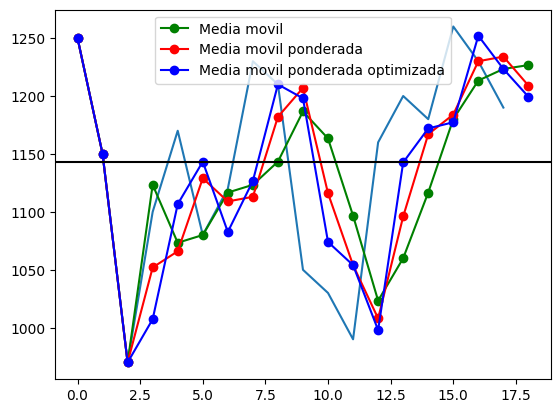

In [83]:
media = np.mean(Data)
plt.plot(Data)
plt.plot(media_,marker='o',color='g',label='Media movil')
plt.plot(media_w,marker='o',color='r',label='Media movil ponderada')
plt.plot(Woptimizada,marker='o',color='b',label='Media movil ponderada optimizada')
plt.axhline(media,color='k')
plt.legend()